<center> <img src = https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/hh%20label.jpg alt="drawing" style="width:400px;">

# Анализ резюме HeadHunter

**Итоговый проект по дисциплине «Python для анализа данных»**  
**Выполнил: Скидан Антон Андреевич**

**Цель работы:** исследовать структуру базы резюме, преобразовать исходные признаки, изучить распределения и зависимости, очистить данные от дубликатов, пропусков и выбросов.

Исходный файл `dst-3.0_16_1_hh_database.zip` сохраняется локально в папке `data/` и не загружается в GitHub из-за большого размера. Для задания 3.6 используется файл `data/ExchangeRates.csv` с историческими курсами валют. Графики выводятся в ноутбуке и сохраняются в `graphs/` для отдельного просмотра. Порядок запуска и ссылки на данные приведены в `README.md`.

**Графики.** Иллюстрации встроены непосредственно в задания 4.1–4.8, в два дополнительных задания и в 5.6. Они доступны при просмотре ноутбука без запуска ячеек. Код построения диаграмм сохранён рядом с графиками.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import re

pd.set_option('display.max_colwidth', 90)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11


# Исходный большой файл не добавляется в репозиторий GitHub.
DATA_CSV = Path('data/dst-3.0_16_1_hh_database.csv')
DATA_ZIP = Path('data/dst-3.0_16_1_hh_database.zip')

# Сохраним построенные диаграммы отдельными PNG для GitHub.
GRAPHS_DIR = Path('graphs')
GRAPHS_DIR.mkdir(exist_ok=True)

# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла. 

In [2]:
# 2.1. Прочитаем файл с разделителем «;» и проверим размер таблицы.
if DATA_CSV.is_file():
    data_path = DATA_CSV
elif DATA_ZIP.is_file():
    data_path = DATA_ZIP
else:
    raise FileNotFoundError(
        'Поместите dst-3.0_16_1_hh_database.csv или ZIP с ним в папку data/. '
        'Инструкция есть в README.md.'
    )

hh_df = pd.read_csv(data_path, sep=';', low_memory=False)
print('Размер таблицы:', hh_df.shape)
assert hh_df.shape == (44744, 12), 'Размер таблицы отличается от исходного файла проекта.' 

Размер таблицы: (44744, 12)


2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [3]:
# 2.2. Просмотрим первые строки и названия признаков.
display(hh_df.head(3))
print('Список признаков:')
print(*hh_df.columns.to_list(), sep='\n')
print('Формат поля «Пол, возраст»:', hh_df['Пол, возраст'].iloc[0])

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
0,"Мужчина , 39 лет , родился 27 ноября 1979",29000 руб.,Системный администратор,"Советск (Калининградская область) , не готов к переезду , не готов к командировкам","частичная занятость, проектная работа, полная занятость","гибкий график, полный день, сменный график, вахтовый метод, удаленная работа",Опыт работы 16 лет 10 месяцев Август 2010 — по настоящее время 8 лет 10 месяцев МАОУ ...,"МАОУ ""СОШ № 1 г.Немана""",Системный администратор,Неоконченное высшее образование 2000 Балтийская государственная академия рыбопромысло...,16.04.2019 15:59,Имеется собственный автомобиль
1,"Мужчина , 60 лет , родился 20 марта 1959",40000 руб.,Технический писатель,"Королев , не готов к переезду , готов к редким командировкам","частичная занятость, проектная работа, полная занятость","гибкий график, полный день, сменный график, удаленная работа",Опыт работы 19 лет 5 месяцев Январь 2000 — по настоящее время 19 лет 5 месяцев Времен...,Временный трудовой коллектив,"Менеджер проекта, Аналитик, Технический писатель","Высшее образование 1981 Военно-космическая академия им. А.Ф. Можайского, Санкт-Петерб...",12.04.2019 08:42,Не указано
2,"Женщина , 36 лет , родилась 12 августа 1982",20000 руб.,Оператор,"Тверь , не готова к переезду , не готова к командировкам",полная занятость,полный день,Опыт работы 10 лет 3 месяца Октябрь 2004 — Декабрь 2014 10 лет 3 месяца ПАО Сбербанк...,ПАО Сбербанк,Кассир-операционист,"Среднее специальное образование 2002 Профессиональный лицей 39 г. Твери Экономический,...",16.04.2019 08:35,Не указано


Список признаков:
Пол, возраст
ЗП
Ищет работу на должность:
Город, переезд, командировки
Занятость
График
Опыт работы
Последнее/нынешнее место работы
Последняя/нынешняя должность
Образование и ВУЗ
Обновление резюме
Авто
Формат поля «Пол, возраст»: Мужчина ,  39 лет , родился 27 ноября 1979


3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

4. Обратите внимание на информацию о числе непустых значений.

In [4]:
# 2.3–2.4. Проверим типы столбцов и количество пропусков.
hh_df.info()
missing_before = hh_df.isna().sum().sort_values(ascending=False)
print('\nПропущенные значения:')
display(missing_before[missing_before > 0].to_frame('Пропусков'))
print('Все типы столбцов:', hh_df.dtypes.unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Пол, возраст                     44744 non-null  object
 1   ЗП                               44744 non-null  object
 2   Ищет работу на должность:        44744 non-null  object
 3   Город, переезд, командировки     44744 non-null  object
 4   Занятость                        44744 non-null  object
 5   График                           44744 non-null  object
 6   Опыт работы                      44576 non-null  object
 7   Последнее/нынешнее место работы  44743 non-null  object
 8   Последняя/нынешняя должность     44742 non-null  object
 9   Образование и ВУЗ                44744 non-null  object
 10  Обновление резюме                44744 non-null  object
 11  Авто                             44744 non-null  object
dtypes: object(12)
memory usage: 4.1+

,Пропусков
Опыт работы,168
Последняя/нынешняя должность,2
Последнее/нынешнее место работы,1


Все типы столбцов: [dtype('O')]


5. Выведите основную статистическую информацию о столбцах.


In [5]:
# 2.5. Определим число уникальных значений и наиболее частую должность.
display(hh_df.describe(include='object').T[['count', 'unique', 'top', 'freq']])
print('Уникальных непустых значений опыта:', hh_df['Опыт работы'].nunique())
print('Самая популярная должность:', hh_df['Ищет работу на должность:'].mode().iloc[0])

,count,unique,top,freq
"Пол, возраст",44744,16003,"Мужчина , 32 года , родился 17 сентября 1986",18
ЗП,44744,690,50000 руб.,4064
Ищет работу на должность:,44744,14929,Системный администратор,3099
"Город, переезд, командировки",44744,10063,"Москва , не готов к переезду , не готов к командировкам",1261
Занятость,44744,38,полная занятость,30026
График,44744,47,полный день,22727
Опыт работы,44576,44413,Опыт работы 10 лет 8 месяцев Апрель 2018 — по настоящее время 1 год 2 месяца ООО Форс...,3
Последнее/нынешнее место работы,44743,30214,Индивидуальное предпринимательство / частная практика / фриланс,935
Последняя/нынешняя должность,44742,16927,Системный администратор,2062
Образование и ВУЗ,44744,40148,"Высшее образование 2014 Московский технический университет связи и информатики, Москв...",4


Уникальных непустых значений опыта: 44413
Самая популярная должность: Системный администратор


# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование, ответьте на контрольные вопросы и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [6]:
# 3.1. Выделим уровень образования из первых слов описания.
def extract_education(value):
    first_words = ' '.join(value.split()[:2])
    if first_words.startswith('Высшее'):
        return 'высшее'
    if first_words.startswith('Неоконченное высшее'):
        return 'неоконченное высшее'
    if first_words.startswith('Среднее специальное'):
        return 'среднее специальное'
    if first_words.startswith('Среднее'):
        return 'среднее'
    raise ValueError(f'Неизвестный уровень образования: {first_words}')

hh_df['Образование'] = hh_df['Образование и ВУЗ'].apply(extract_education)
hh_df.drop(columns='Образование и ВУЗ', inplace=True)
display(hh_df['Образование'].value_counts().to_frame('Резюме'))
print('Со средним образованием:', (hh_df['Образование'] == 'среднее').sum())

,Резюме
Образование,
высшее,33863
среднее специальное,5765
неоконченное высшее,4557
среднее,559


Со средним образованием: 559


2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979 
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина. 
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование, ответьте на контрольные вопросы и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '. 
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [7]:
# 3.2. Разделим пол и возраст на два самостоятельных признака.
def extract_gender(value):
    return 'М' if value.split(' , ')[0].strip() == 'Мужчина' else 'Ж'

def extract_age(value):
    return int(value.split(' , ')[1].strip().split()[0])

hh_df['Пол'] = hh_df['Пол, возраст'].apply(extract_gender)
hh_df['Возраст'] = hh_df['Пол, возраст'].apply(extract_age)
hh_df.drop(columns='Пол, возраст', inplace=True)

female_pct = hh_df['Пол'].eq('Ж').mean() * 100
mean_age = hh_df['Возраст'].mean()
print(f'Женских резюме: {female_pct:.2f}%')
print(f'Средний возраст: {mean_age:.1f} года')
print('Уникальные значения пола:', hh_df['Пол'].unique())

Женских резюме: 19.07%
Средний возраст: 32.2 года
Уникальные значения пола: ['М' 'Ж']


3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**. 

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование, ответьте на контрольные вопросы и удалите столбец **"Опыт работы"** из таблицы.


In [8]:
# 3.3. Переведём общий стаж в количество месяцев.
def extract_experience_months(value):
    if pd.isna(value) or str(value).strip() == 'Не указано':
        return np.nan
    header = str(value).split('  ')[0]
    years_match = re.search(r'(\d+)\s+(?:лет|год|года)', header)
    months_match = re.search(r'(\d+)\s+месяц', header)
    years = int(years_match.group(1)) if years_match else 0
    months = int(months_match.group(1)) if months_match else 0
    return years * 12 + months

hh_df['Опыт работы (месяц)'] = hh_df['Опыт работы'].apply(extract_experience_months)
hh_df.drop(columns='Опыт работы', inplace=True)
print('Медианный опыт работы:', hh_df['Опыт работы (месяц)'].median(), 'месяцев')
print('Стаж не указан:', hh_df['Опыт работы (месяц)'].isna().sum())

Медианный опыт работы: 100.0 месяцев
Стаж не указан: 170


4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , … 
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [9]:
# 3.4. Сгруппируем города и определим готовность к переезду и командировкам.
million_cities = [
    'Новосибирск', 'Екатеринбург', 'Нижний Новгород', 'Казань',
    'Челябинск', 'Омск', 'Самара', 'Ростов-на-Дону', 'Уфа',
    'Красноярск', 'Пермь', 'Воронеж', 'Волгоград'
]

def extract_city(value):
    city = value.split(' , ')[0].strip()
    if city in ('Москва', 'Санкт-Петербург'):
        return city
    return 'город-миллионник' if city in million_cities else 'другие'

def is_ready_to_relocate(value):
    return ('не готов к переезду' not in value
            and 'не готова к переезду' not in value)

def is_ready_for_trips(value):
    # При отсутствии информации о командировках примем значение False.
    return ('командировк' in value and 'не готов к командировкам' not in value
            and 'не готова к командировкам' not in value)

location = hh_df['Город, переезд, командировки']
hh_df['Город'] = location.apply(extract_city)
hh_df['Готовность к переезду'] = location.apply(is_ready_to_relocate)
hh_df['Готовность к командировкам'] = location.apply(is_ready_for_trips)
hh_df.drop(columns='Город, переезд, командировки', inplace=True)

both_ready = (hh_df['Готовность к переезду'] & hh_df['Готовность к командировкам']).mean() * 100
print(f'Доля резюме из Санкт-Петербурга: {hh_df["Город"].eq("Санкт-Петербург").mean() * 100:.0f}%')
print(f'Готовы и переехать, и ездить в командировки: {both_ready:.0f}%')
display(hh_df['Город'].value_counts().to_frame('Резюме'))

Доля резюме из Санкт-Петербурга: 11%
Готовы и переехать, и ездить в командировки: 32%


,Резюме
Город,
Москва,16621
другие,15854
город-миллионник,7332
Санкт-Петербург,4937


5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:
<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/ohe.jpg>
Выполните данное преобразование для признаков "Занятость" и "График", ответьте на контрольные вопросы, после чего удалите их из таблицы

In [10]:
# 3.5. Создадим булевы признаки для категорий занятости и графика.
employment_categories = [
    'полная занятость', 'частичная занятость', 'проектная работа',
    'волонтерство', 'стажировка'
]
schedule_categories = [
    'полный день', 'сменный график', 'гибкий график',
    'удаленная работа', 'вахтовый метод'
]

for category in employment_categories:
    hh_df[category] = hh_df['Занятость'].str.contains(category, regex=False)
for category in schedule_categories:
    hh_df[category] = hh_df['График'].str.contains(category, regex=False)

print('Проектная работа и волонтёрство:',
      (hh_df['проектная работа'] & hh_df['волонтерство']).sum())
print('Вахтовый метод и гибкий график:',
      (hh_df['вахтовый метод'] & hh_df['гибкий график']).sum())
hh_df.drop(columns=['Занятость', 'График'], inplace=True)

Проектная работа и волонтёрство: 436
Вахтовый метод и гибкий график: 2311


6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**. 
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата, 
* "proportion" - пропорция, 
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.

<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/table.jpg>


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После ответа на контрольные вопросы удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Для перевода зарплат в рубли выделим сумму и валюту из столбца `ЗП`. Приведём названия валют к ISO-кодам и сопоставим данные с курсом на дату обновления резюме.

\[
\text{ЗП (руб)} = \text{Сумма} \cdot \frac{\text{close}}{\text{proportion}}.
\]

Коэффициенты из условия: UAH — 10, USD — 1, EUR — 1, BYN — 1, KGS — 10, UZS — 10 000, AZN — 1, KZT — 100. Зарплату в рублях оставим без пересчёта.

**Курсы валют:** используется файл `data/ExchangeRates.csv` из материалов курса со столбцами `currency`, `date`, `close`, `proportion`. Даты сопоставляются с датами обновления резюме, а пропорции берутся из самого CSV. Файл должен находиться в папке `data/` рядом с исходным архивом резюме.


In [11]:
# 3.6. Переведём зарплаты в рубли по дате обновления резюме.
# Загрузим исторические курсы из приложенного CSV.
RATES_FILE = Path('data/ExchangeRates.csv')
if not RATES_FILE.is_file():
    raise FileNotFoundError('Поместите ExchangeRates.csv в папку data/ рядом с ноутбуком.')

currency_codes = {
    'руб.': 'RUB', 'грн.': 'UAH', 'USD': 'USD', 'EUR': 'EUR',
    'бел.руб.': 'BYN', 'белруб': 'BYN', 'KGS': 'KGS',
    'сум': 'UZS', 'AZN': 'AZN', 'KZT': 'KZT'
}

salary_parts = hh_df['ЗП'].str.replace('\xa0', ' ', regex=False).str.split()
hh_df['Сумма'] = salary_parts.apply(lambda parts: float(parts[0].replace(',', '.')))
hh_df['Валюта'] = salary_parts.apply(lambda parts: currency_codes[parts[-1]])
hh_df['Обновление резюме'] = pd.to_datetime(
    hh_df['Обновление резюме'], format='%d.%m.%Y %H:%M'
).dt.normalize()
hh_df['Дата обновления'] = hh_df['Обновление резюме']

rates_path = RATES_FILE
fx_ready = True

if fx_ready:
    # Определим разделитель исходной таблицы курсов.
    rates = pd.read_csv(rates_path, sep=None, engine='python')
    rates.columns = rates.columns.str.strip()
    required = {'currency', 'date', 'close', 'proportion'}
    if not required.issubset(rates.columns):
        raise ValueError(f'В файле с курсами нет столбцов: {required - set(rates.columns)}')

    rates['currency'] = rates['currency'].astype(str).str.strip().str.upper()
    rates['date'] = pd.to_datetime(rates['date'], format='%d/%m/%y').dt.normalize()
    for col in ('close', 'proportion'):
        rates[col] = pd.to_numeric(
            rates[col].astype(str).str.replace(',', '.', regex=False),
            errors='coerce'
        )
    rates = rates.drop_duplicates(subset=['currency', 'date'], keep='last')

    hh_df = hh_df.merge(
        rates[['currency', 'date', 'close', 'proportion']],
        how='left', left_on=['Валюта', 'Дата обновления'],
        right_on=['currency', 'date'], validate='many_to_one'
    )
    rub_rows = hh_df['Валюта'].eq('RUB')
    hh_df.loc[rub_rows, ['close', 'proportion']] = 1
    missing_rates = hh_df.loc[~rub_rows & hh_df['close'].isna(),
                              ['Валюта', 'Дата обновления']]
    if not missing_rates.empty:
        raise ValueError(
            f'Для {len(missing_rates)} резюме не найден курс на дату обновления. '
            'Проверьте, что выбран полный учебный CSV с историческими курсами.'
        )
    hh_df['ЗП (руб)'] = hh_df['Сумма'] * hh_df['close'] / hh_df['proportion']
    hh_df.drop(columns=['currency', 'date', 'close', 'proportion'], inplace=True)
else:
    # Без курсов сохраним только уже известные рублёвые суммы.
    hh_df['ЗП (руб)'] = hh_df['Сумма'].where(hh_df['Валюта'].eq('RUB'))
    print('Не указан CSV курсов: пересчёт иностранных зарплат пока не выполнен.')
    print('Резюме без полного расчёта:', hh_df['ЗП (руб)'].isna().sum())

hh_df.drop(columns=['ЗП', 'Сумма', 'Валюта', 'Дата обновления'], inplace=True)
if fx_ready:
    median_k = hh_df['ЗП (руб)'].median() / 1000
    print(f'Медианная желаемая зарплата: {median_k:.0f} тыс. руб.')
else:
    print('Общую медиану можно рассчитать после загрузки курсов.')

Медианная желаемая зарплата: 59 тыс. руб.


# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

In [12]:
# 4.1. Построим гистограмму и коробчатую диаграмму возраста.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(hh_df['Возраст'], bins=40)
axes[0].set(title='Распределение возраста соискателей',
            xlabel='Возраст, лет', ylabel='Число резюме')
sns.boxplot(x=hh_df['Возраст'], ax=axes[1])
axes[1].set(title='Возраст: коробчатая диаграмма', xlabel='Возраст, лет')
fig.tight_layout()
fig.savefig(GRAPHS_DIR / '4_1_Age_Distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Мода:', hh_df['Возраст'].mode().iloc[0])
print('Минимум и максимум:', hh_df['Возраст'].min(), hh_df['Возраст'].max())
print('Квартиль 25% и 75%:', hh_df['Возраст'].quantile([.25, .75]).tolist())

Мода: 30
Минимум и максимум: 14 100
Квартиль 25% и 75%: [27.0, 36.0]


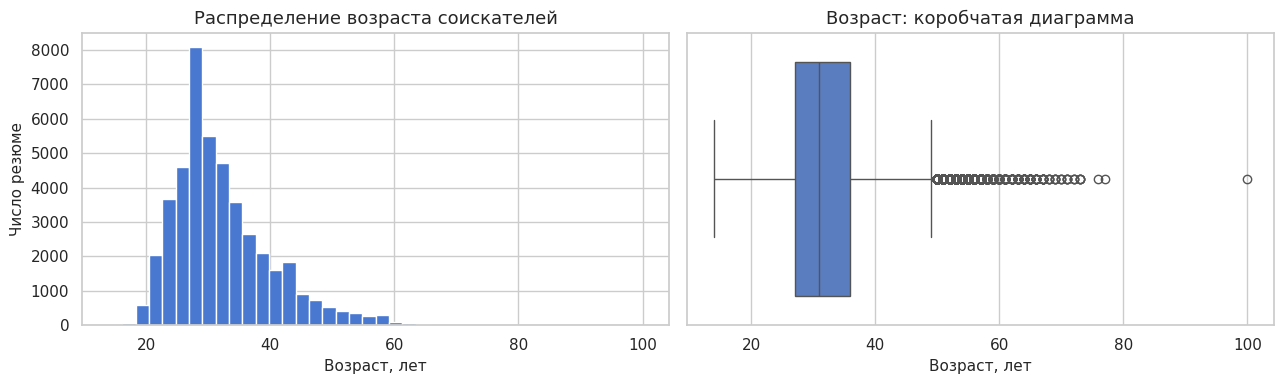

*Распределение возраста соискателей.*

**Вывод.** Модальный возраст составляет **30 лет**. Основная часть резюме принадлежит людям примерно от 25 до 40 лет. Распределение смещено вправо; встречаются отдельные наблюдения с возрастом до 100 лет, которые следует проверить при очистке.

2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

In [13]:
# 4.2. Построим распределение стажа и отметим крайние значения.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(hh_df['Опыт работы (месяц)'].dropna(), bins=50)
axes[0].set(title='Распределение общего стажа',
            xlabel='Опыт работы, месяцев', ylabel='Число резюме')
sns.boxplot(x=hh_df['Опыт работы (месяц)'], ax=axes[1])
axes[1].set(title='Стаж: коробчатая диаграмма', xlabel='Опыт работы, месяцев')
fig.tight_layout()
fig.savefig(GRAPHS_DIR / '4_2_Experience_Distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Мода:', hh_df['Опыт работы (месяц)'].mode().iloc[0])
print('Минимум и максимум:', hh_df['Опыт работы (месяц)'].min(), hh_df['Опыт работы (месяц)'].max())
print('Квартиль 25% и 75%:', hh_df['Опыт работы (месяц)'].quantile([.25, .75]).tolist())

Мода: 81.0
Минимум и максимум: 1.0 1188.0
Квартиль 25% и 75%: [57.0, 154.0]


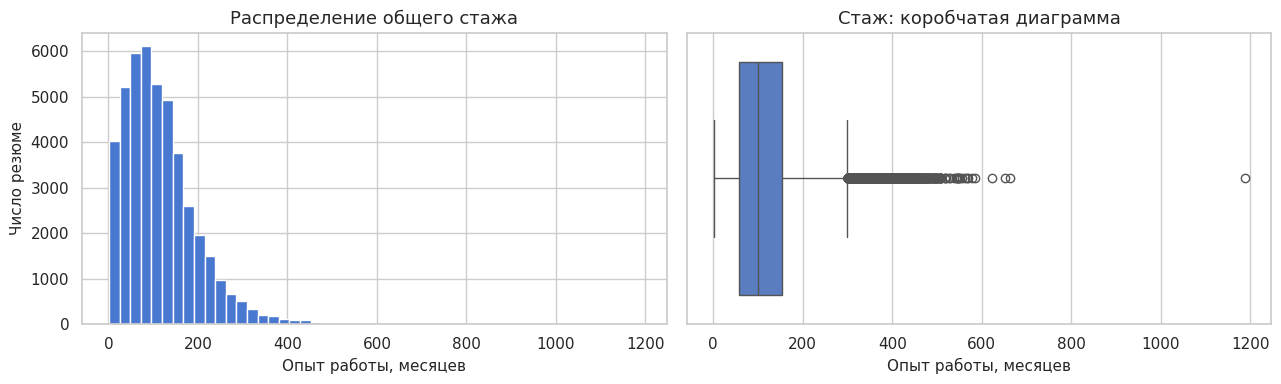

*Распределение опыта работы.*

**Вывод.** Наиболее частый опыт работы — **81 месяц**. Для большинства соискателей стаж не превышает нескольких десятков лет. Максимальное значение **1188 месяцев** (99 лет) существенно отличается от основной выборки и похоже на ошибку в данных.

3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для признака возраста? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


In [14]:
# 4.3. Посмотрим распределение зарплат и возможные выбросы.
if fx_ready:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(hh_df['ЗП (руб)'], bins=60)
    axes[0].set(title='Распределение желаемых зарплат',
                xlabel='Зарплата, руб.', ylabel='Число резюме')
    sns.boxplot(x=hh_df['ЗП (руб)'], ax=axes[1])
    axes[1].set(title='Зарплата: коробчатая диаграмма', xlabel='Зарплата, руб.')
    fig.tight_layout()
    fig.savefig(GRAPHS_DIR / '4_3_Salary_Distribution.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Минимум и максимум:', hh_df['ЗП (руб)'].min(), hh_df['ЗП (руб)'].max())
    print('Квартиль 25% и 75%:', hh_df['ЗП (руб)'].quantile([.25, .75]).tolist())
else:
    print('График 4.3 появится после подключения учебного CSV с курсами.')

Минимум и максимум: 1.0 24304876.0
Квартиль 25% и 75%: [37082.2, 95000.0]


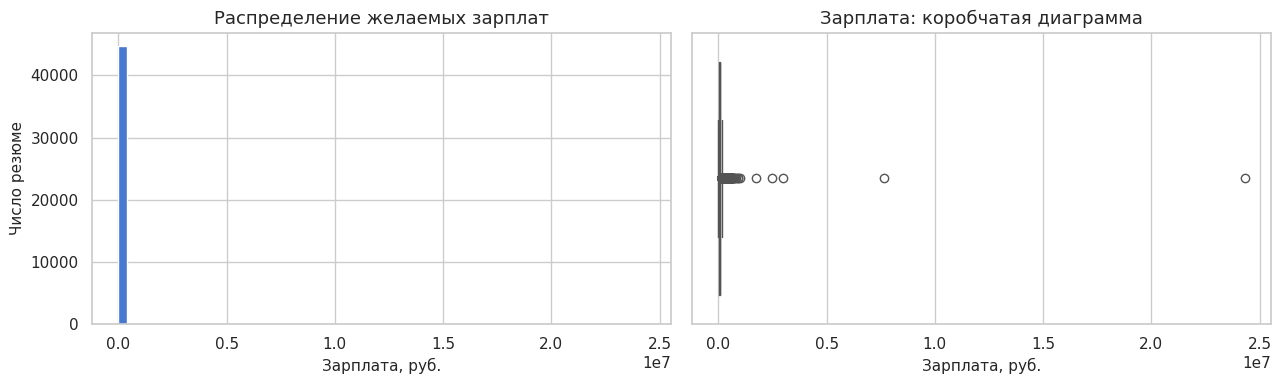

*Распределение желаемой зарплаты.*

**Вывод.** Гистограмма позволяет оценить наиболее распространённые зарплатные ожидания, а коробчатая диаграмма — заметить редкие высокие значения. Чрезмерно большие и очень маленькие зарплаты нужно проверить при очистке; анализ проводим после перевода всех валют в рубли.

4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

In [15]:
# 4.4. Сравним медианы зарплат по уровню образования.
if fx_ready:
    salary_under_million = hh_df.loc[hh_df['ЗП (руб)'] < 1_000_000].copy()
    education_order = ['среднее', 'среднее специальное', 'неоконченное высшее', 'высшее']
    education_median = (salary_under_million.groupby('Образование')['ЗП (руб)']
                        .median().reindex(education_order))
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(education_median.index, education_median.values)
    ax.set(title='Медианная желаемая зарплата по образованию',
           xlabel='Уровень образования', ylabel='Медианная зарплата, руб.')
    ax.tick_params(axis='x', rotation=12)
    fig.tight_layout()
    fig.savefig(GRAPHS_DIR / '4_4_Salary_by_Education.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Медианы по образованию:')
    display(education_median.to_frame('Медианная зарплата, руб.'))
    print('Наибольшая медиана:', education_median.idxmax())
else:
    print('График 4.4 станет доступен после подключения учебного CSV с курсами.')

Медианы по образованию:


,"Медианная зарплата, руб."
Образование,
среднее,40000.0
среднее специальное,40000.0
неоконченное высшее,50000.0
высшее,60000.0


Наибольшая медиана: высшее


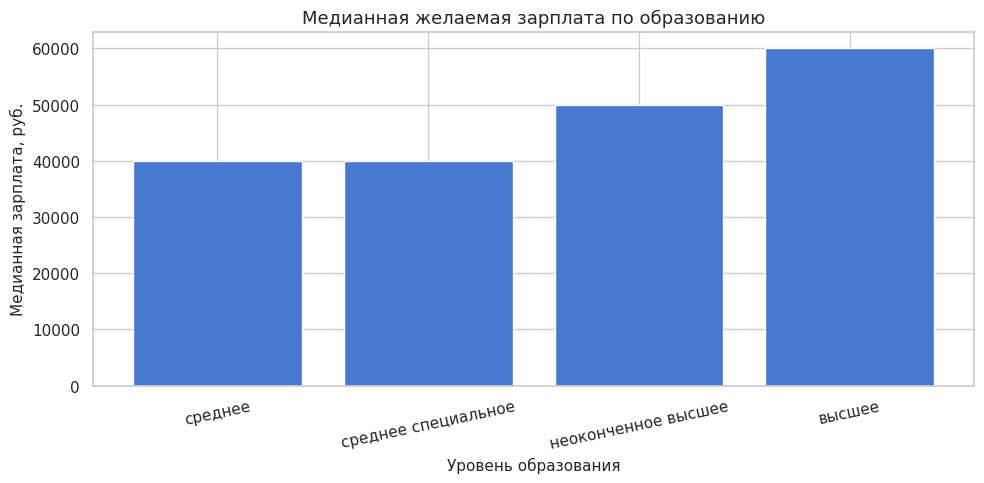

*Медианная зарплата по образованию.*

**Вывод.** При сравнении медианных зарплат по уровню образования наибольшее значение соответствует категории **«высшее»**. Значит, образование связано с зарплатными ожиданиями, хотя само по себе не объясняет все различия между резюме.

5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

In [16]:
# 4.5. Сравним распределения зарплат между категориями городов.
if fx_ready:
    city_order = ['Москва', 'Санкт-Петербург', 'город-миллионник', 'другие']
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.boxplot(data=salary_under_million, x='Город', y='ЗП (руб)',
                order=city_order, ax=ax)
    ax.set(title='Распределение желаемой зарплаты по категориям городов',
           xlabel='Категория города', ylabel='Зарплата, руб.')
    fig.tight_layout()
    fig.savefig(GRAPHS_DIR / '4_5_Salary_by_City.png', dpi=150, bbox_inches='tight')
    plt.show()
    city_maximums = salary_under_million.groupby('Город')['ЗП (руб)'].max()
    display(city_maximums.sort_values(ascending=False).to_frame('Максимум, руб.'))
    print('Категория с максимальным значением:', city_maximums.idxmax())
else:
    print('Для построения графика 4.5 нужно добавить файл с курсами валют.')

,"Максимум, руб."
Город,
другие,923983.0
Москва,900000.0
Санкт-Петербург,645171.0
город-миллионник,511681.6


Категория с максимальным значением: другие


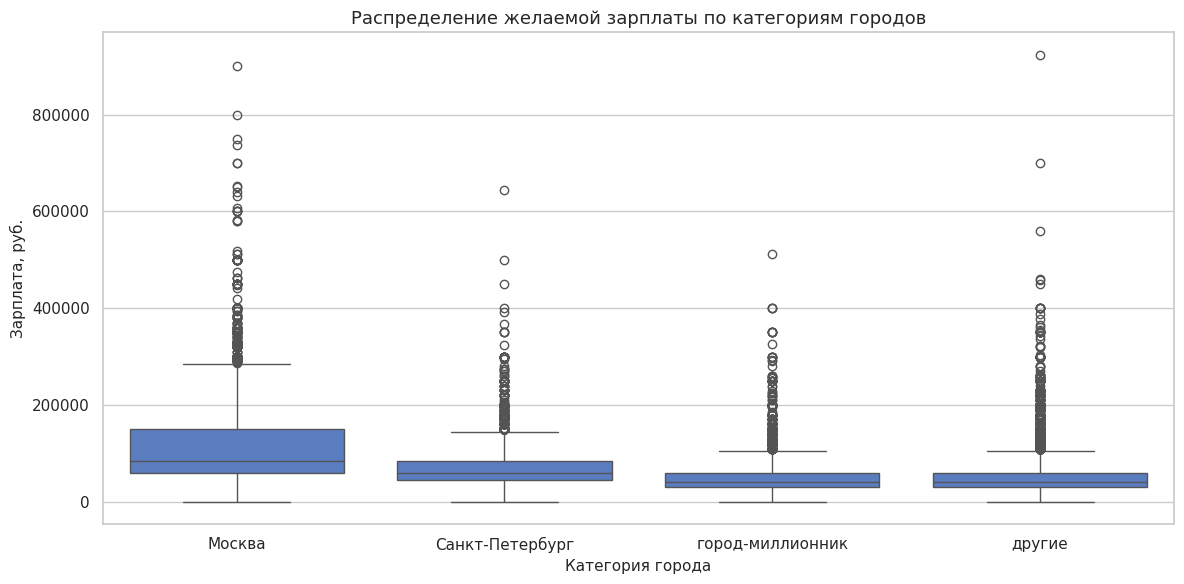

*Распределение зарплат по категориям городов.*

**Вывод.** На коробчатой диаграмме сравним медианы, разброс и крайние значения четырёх категорий городов. При ограничении зарплатой менее миллиона рублей наибольшее значение — около **924 тыс. рублей** — относится к категории **«другие»**. Это максимальное значение отдельного резюме, а не медиана группы.

6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

In [17]:
# 4.6. Сгруппируем медианные зарплаты по готовности к поездкам.
if fx_ready:
    readiness_salary = (hh_df.groupby(['Готовность к переезду', 'Готовность к командировкам'])
                        ['ЗП (руб)'].median().reset_index())
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=readiness_salary, x='Готовность к переезду',
                y='ЗП (руб)', hue='Готовность к командировкам', ax=ax)
    ax.set(title='Медианная зарплата: переезд и командировки',
           xlabel='Готовность к переезду', ylabel='Медианная зарплата, руб.')
    ax.legend(title='Командировки')
    fig.tight_layout()
    fig.savefig(GRAPHS_DIR / '4_6_Salary_by_Relocation_and_Trips.png', dpi=150, bbox_inches='tight')
    plt.show()
    display(readiness_salary)
    both = hh_df['Готовность к переезду'] & hh_df['Готовность к командировкам']
    print('Медиана для готовых к обоим условиям, тыс. руб.:',
          round(hh_df.loc[both, 'ЗП (руб)'].median() / 1000))
else:
    print('Для построения графика 4.6 нужно добавить файл с курсами валют.')

,Готовность к переезду,Готовность к командировкам,ЗП (руб)
0,False,False,40000.000
1,False,True,60000.000
2,True,False,50000.000
3,True,True,65849.455


Медиана для готовых к обоим условиям, тыс. руб.: 66


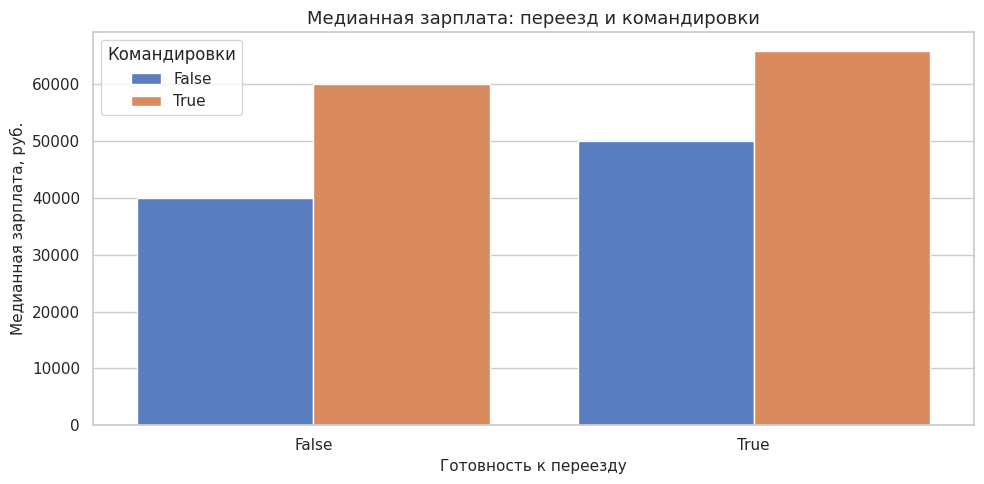

*Зарплата и готовность к переездам и командировкам.*

**Вывод.** Сравнение четырёх сочетаний готовности к переезду и командировкам показывает, как зарплатные ожидания отличаются между группами. Здесь важно сравнивать именно медианы, чтобы отдельные большие зарплаты не искажали результат.

7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

In [18]:
# 4.7. Построим тепловую карту медианных зарплат.
if fx_ready:
    salary_pivot = hh_df.pivot_table(index='Возраст', columns='Образование',
                                    values='ЗП (руб)', aggfunc='median')
    fig, ax = plt.subplots(figsize=(12, 13))
    sns.heatmap(salary_pivot, cmap='YlGnBu', ax=ax,
                cbar_kws={'label': 'Медианная зарплата, руб.'})
    ax.set(title='Медианная зарплата по возрасту и образованию',
           xlabel='Уровень образования', ylabel='Возраст, лет')
    fig.tight_layout()
    fig.savefig(GRAPHS_DIR / '4_7_Salary_by_Age_and_Education.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('График 4.7 станет доступен после подключения учебного CSV с курсами.')

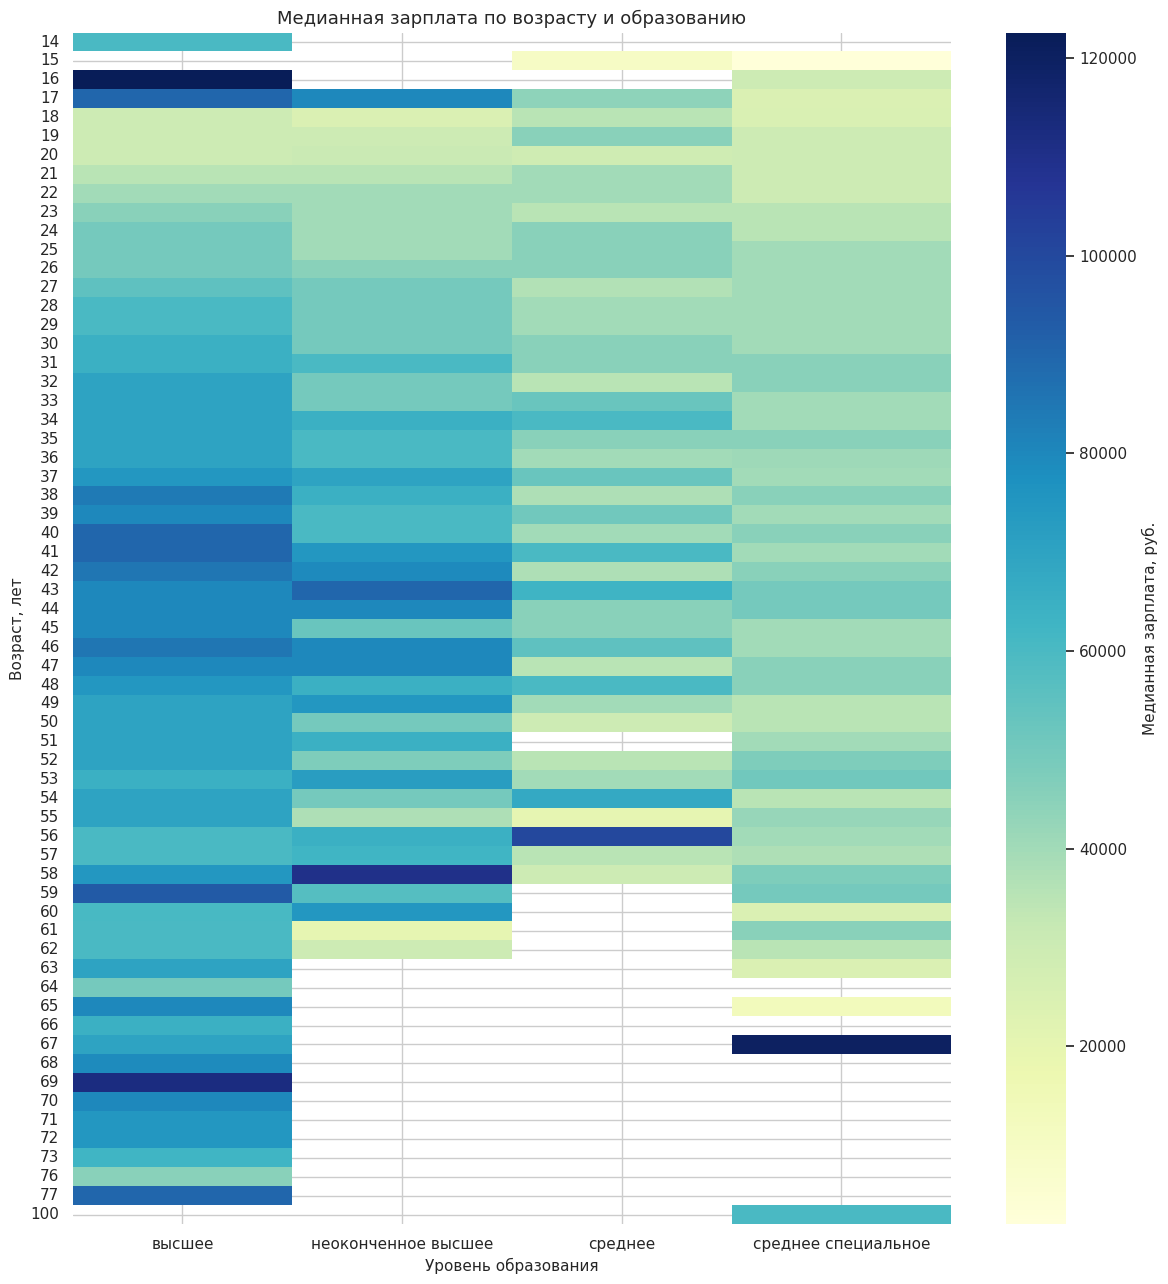

*Тепловая карта зарплат по возрасту и образованию.*

**Вывод.** Тепловая карта позволяет сравнить медианные зарплаты внутри возрастных групп и уровней образования. Особенно осторожно нужно трактовать редкие сочетания возраста и образования: небольшое число резюме может заметно влиять на медиану.

8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

In [19]:
# 4.8. Сравним опыт работы и возраст на диаграмме рассеяния.
experience_years = hh_df['Опыт работы (месяц)'] / 12
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(hh_df['Возраст'], experience_years, s=7, alpha=0.18)
ax.plot([0, 100], [0, 100], linestyle='--', color='firebrick', label='Опыт = возраст')
ax.set(xlim=(0, 105), ylim=(0, 105), title='Опыт работы и возраст соискателей',
       xlabel='Возраст, лет', ylabel='Опыт работы, лет')
ax.legend()
fig.tight_layout()
fig.savefig(GRAPHS_DIR / '4_8_Age_vs_Experience.png', dpi=150, bbox_inches='tight')
plt.show()
print('Резюме со стажем СТРОГО выше возраста:',
      (experience_years > hh_df['Возраст']).sum())

Резюме со стажем СТРОГО выше возраста: 7


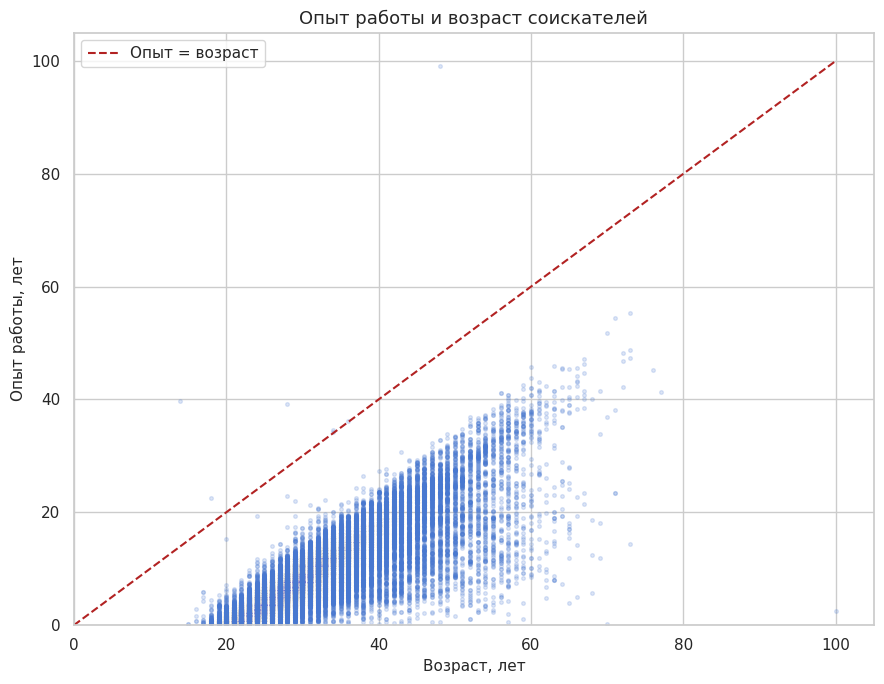

*Зависимость опыта работы от возраста.*

**Вывод.** С увеличением возраста соискателя обычно увеличивается и опыт работы. Однако встречаются ошибки: по исходным данным **7 точек** расположены строго выше прямой `опыт = возраст`. Такие резюме предстоит удалить при очистке.

## Дополнительный анализ (доп задание на 2 балла)

Построим ещё два графика, используя признаки, полученные в разделе преобразования данных. Для каждого графика приведём краткий вывод.

In [20]:
# Дополнительный график 1. Сравним долю удалённой работы по городам.
remote_pct = (hh_df.groupby('Город')['удаленная работа'].mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(remote_pct.index, remote_pct.values)
ax.set(title='Доля желающих работать удалённо по категориям городов',
       xlabel='Категория города', ylabel='Доля резюме с удалённой работой, %')
ax.tick_params(axis='x', rotation=10)
fig.tight_layout()
fig.savefig(GRAPHS_DIR / 'Extra_1_Remote_Work_by_City.png', dpi=150, bbox_inches='tight')
plt.show()
display(remote_pct.round(1).to_frame('Доля удалённой работы, %'))

,"Доля удалённой работы, %"
Город,
другие,35.5
Санкт-Петербург,34.9
город-миллионник,33.6
Москва,31.3


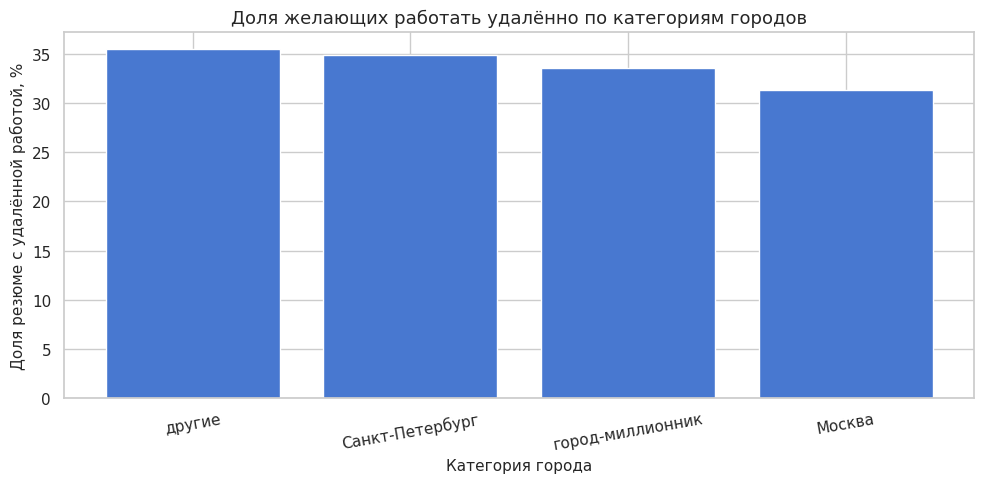

*Дополнительный график: удалённая работа по городам.*

**Вывод.** Самая высокая доля соискателей, рассматривающих удалённую работу, наблюдается в категории **«другие» (35,5%)**, затем в Санкт-Петербурге (34,9%), городах-миллионниках (33,6%) и Москве (31,3%). Различия относительно невелики, но предпочтение удалённой работы есть во всех группах.

In [21]:
# Дополнительный график 2. Сравним медианный стаж по полу и образованию.
experience_groups = (hh_df.groupby(['Образование', 'Пол'])['Опыт работы (месяц)']
                     .median().reset_index())
fig, ax = plt.subplots(figsize=(11, 5))
experience_groups.pivot(index='Образование', columns='Пол', values='Опыт работы (месяц)').plot(kind='bar', ax=ax)
ax.set(title='Медианный опыт работы по образованию и полу',
       xlabel='Уровень образования', ylabel='Медианный опыт, месяцев')
ax.tick_params(axis='x', rotation=10)
ax.legend(title='Пол')
fig.tight_layout()
fig.savefig(GRAPHS_DIR / 'Extra_2_Experience_by_Education_and_Gender.png', dpi=150, bbox_inches='tight')
plt.show()
display(experience_groups)

,Образование,Пол,Опыт работы (месяц)
0,высшее,Ж,92.0
1,высшее,М,115.0
2,неоконченное высшее,Ж,60.0
3,неоконченное высшее,М,80.0
4,среднее,Ж,61.0
5,среднее,М,73.0
6,среднее специальное,Ж,64.0
7,среднее специальное,М,69.0


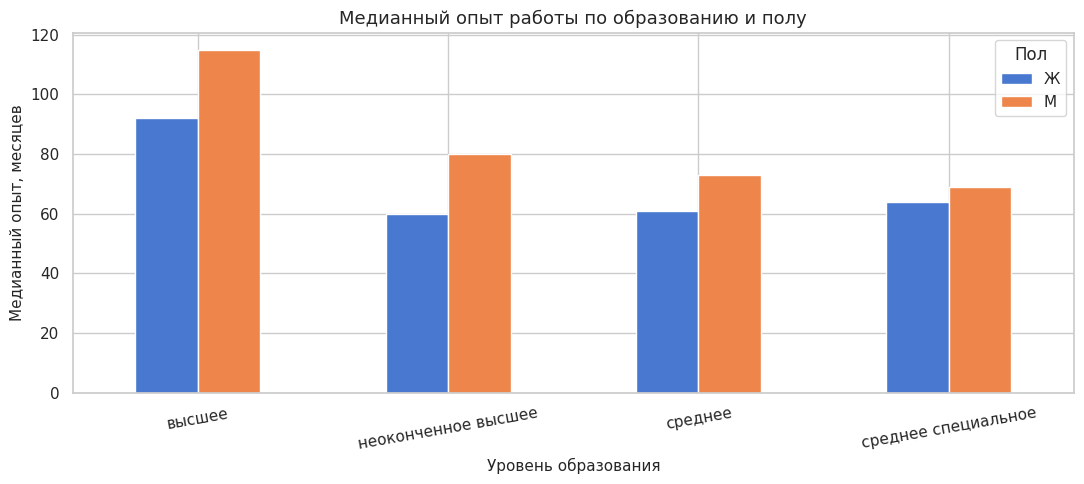

*Дополнительный график: стаж по образованию и полу.*

**Вывод.** Во всех четырёх группах образования медианный опыт работы мужчин выше, чем женщин. Наиболее заметная разница наблюдается среди соискателей с высшим образованием: **115 месяцев у мужчин против 92 у женщин**. Сравнение описывает состав резюме, но само по себе не объясняет причины различий.

# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их. 

In [22]:
# 5.1. Найдём и удалим полные дубликаты после преобразований.
duplicate_count = hh_df.duplicated().sum()
print('Обнаружено полных дубликатов:', duplicate_count)
hh_df = hh_df.drop_duplicates().copy()
print('Осталось резюме:', len(hh_df))

Обнаружено полных дубликатов: 161
Осталось резюме: 44583


2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах. 

In [23]:
# 5.2. Проверим количество пропусков после удаления дубликатов.
missing_after_duplicates = hh_df.isna().sum()
expected_missing_columns = ['Опыт работы (месяц)',
                            'Последнее/нынешнее место работы',
                            'Последняя/нынешняя должность']
display(missing_after_duplicates[expected_missing_columns].to_frame('Пропусков'))
print('Пропусков стажа:', missing_after_duplicates['Опыт работы (месяц)'])
if not fx_ready:
    print('Дополнительно не рассчитаны', hh_df['ЗП (руб)'].isna().sum(),
          'зарплат в иностранной валюте (это не пропуски исходного CSV).')

,Пропусков
Опыт работы (месяц),168
Последнее/нынешнее место работы,1
Последняя/нынешняя должность,2


Пропусков стажа: 168


3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [24]:
# 5.3. Удалим строки без места работы и должности, стаж заполним медианой.
hh_df = hh_df.dropna(subset=['Последнее/нынешнее место работы',
                             'Последняя/нынешняя должность']).copy()
experience_median = hh_df['Опыт работы (месяц)'].median()
hh_df['Опыт работы (месяц)'] = hh_df['Опыт работы (месяц)'].fillna(experience_median)
print('Медиана для заполнения:', experience_median)
print('Средний стаж после заполнения:', round(hh_df['Опыт работы (месяц)'].mean()))
print('Пропусков стажа осталось:', hh_df['Опыт работы (месяц)'].isna().sum())

Медиана для заполнения: 100.0
Средний стаж после заполнения: 114
Пропусков стажа осталось: 0


4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [25]:
# 5.4. Удалим зарплаты выше 1 млн и ниже 1 тыс. рублей.
if fx_ready:
    salary_outliers = (hh_df['ЗП (руб)'] < 1_000) | (hh_df['ЗП (руб)'] > 1_000_000)
    print('Найдено выбросов зарплаты:', salary_outliers.sum())
    hh_df = hh_df.loc[~salary_outliers].copy()
else:
    print('Полную очистку зарплат выполняю после подключения исторических курсов.')
    print('Рублёвые значения проверены; иностранные пока нельзя сравнивать с порогами.')

Найдено выбросов зарплаты: 89


5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [26]:
# 5.5. Удалим записи, в которых стаж в годах превышает возраст.
invalid_experience = hh_df['Опыт работы (месяц)'] / 12 > hh_df['Возраст']
print('Найдено аномальных резюме:', invalid_experience.sum())
hh_df = hh_df.loc[~invalid_experience].copy()

Найдено аномальных резюме: 7


6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

In [27]:
# 5.6. Выделим выбросы логарифма возраста: −3σ слева, +4σ справа.
log_age = np.log(hh_df['Возраст'])
log_mean, log_std = log_age.mean(), log_age.std()
left_bound = log_mean - 3 * log_std
right_bound = log_mean + 4 * log_std

fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(log_age, bins=50)
ax.axvline(log_mean, color='black', lw=2, label='Среднее')
ax.axvline(left_bound, color='firebrick', linestyle='--', lw=2, label='−3σ')
ax.axvline(right_bound, color='darkgreen', linestyle='--', lw=2, label='+4σ')
ax.set(title='Логарифм возраста: поиск выбросов методом z-отклонения',
       xlabel='ln(Возраст)', ylabel='Число резюме')
ax.legend()
fig.tight_layout()
fig.savefig(GRAPHS_DIR / '5_6_Age_Outliers.png', dpi=150, bbox_inches='tight')
plt.show()

age_outliers = (log_age < left_bound) | (log_age > right_bound)
print('Асимметрия логарифма возраста:', round(log_age.skew(), 3))
print('Найдено выбросов возраста:', age_outliers.sum())
print('Возраст выбросов:', sorted(hh_df.loc[age_outliers, 'Возраст'].tolist()))
display(hh_df.loc[age_outliers, ['Возраст', 'Пол', 'Образование', 'Опыт работы (месяц)']])
hh_df = hh_df.loc[~age_outliers].copy()
print('Размер таблицы после очистки:', hh_df.shape)

Асимметрия логарифма возраста: 0.452
Найдено выбросов возраста: 3
Возраст выбросов: [15, 15, 100]


,Возраст,Пол,Образование,Опыт работы (месяц)
31137,15,М,среднее,2.0
32950,15,М,среднее специальное,3.0
33654,100,М,среднее специальное,30.0


Размер таблицы после очистки: (44482, 23)


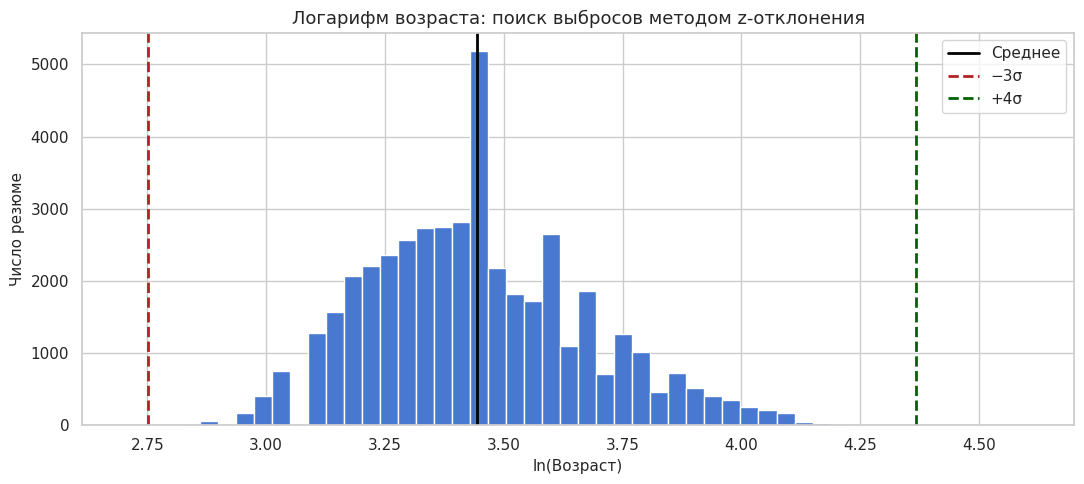

*Выбросы возраста в логарифмическом масштабе.*

**Вывод.** Логарифм возраста имеет умеренную правостороннюю асимметрию. При границах **−3σ** слева и **+4σ** справа выделены три резюме с возрастом **15, 15 и 100 лет**. Эти наблюдения удалим из очищенной выборки.

## Итог

В ходе работы изучена структура базы HeadHunter, текстовые поля преобразованы в категориальные и числовые признаки. Исследованы распределения возраста и стажа, зависимость опыта от возраста и показатели, основанные на преобразованных признаках. Построены **два дополнительных графика** с выводами.

Последовательная очистка включает удаление дубликатов, заполнение пропусков, проверку зарплат, поиск аномального стажа и выбросов возраста. В задании 3.6 для пересчёта зарплат в рубли используется **учебный файл `data/ExchangeRates.csv`** с ежедневными курсами валют. После размещения обоих исходных файлов в папке `data/` все задания выполняются последовательно.

Все построенные графики сохраняются непосредственно в ноутбуке и отдельно в папке `graphs/`.
